# Taller 1:  Agente analista del SECOP (LangChain + LangSmith)
**Reto: agente analista de contratación pública**

**Equipo:** Damy Villegas - Sara Díaz

### Qué pide el Taller 1 (según `Reto_IA_2026.pdf`)
| Requisito del taller | Dónde se cumple en este notebook |
|---|---|
| Agente con **al menos dos herramientas propias** que **decida solo** cuándo usarlas | Sección 5: además de las 3 herramientas base del curso, construimos `leer_pliego` y `verificar_experiencia` |
| **Trazas en LangSmith** | Todo corre con `LANGSMITH_TRACING=true` en el proyecto `secop-taller1-damy-sara` |
| **Dataset de 15 a 20 preguntas** | Sección 8: las 18 preguntas del conjunto de referencia + 2 preguntas propias sobre pliegos = 20 |
| **Comparación de dos configuraciones**: precisión, costo y latencia | Secciones 9 y 10: agente base del curso (A) vs. agente del equipo (B), con el mismo modelo |
| Criterio clave: **≥ 85 % de precisión con el menor costo posible** | Sección 10: tabla final y decisiones de diseño |

Se usa `MODO_DATOS=muestra` (los 20 procesos locales), que el README del taller marca como obligatorio para el conjunto de referencia.

> **Antes de ejecutar:** en el panel  **Secretos** de Colab crear `LANGSMITH_API_KEY` y la clave del modelo (`ANTHROPIC_API_KEY`, o `GEMINI_API_KEY` si en la sección 2 se elige `PROVEEDOR = "gemini"`), con *Acceso del cuaderno* activado. Cargar el Zip "taller_agente".






## 1. Instalación

In [5]:
%pip install -qU langchain langchain-anthropic langchain-google-genai langsmith pypdf python-dotenv requests pandas

## 2. Claves y proveedor del modelo
Las claves se leen de los Secretos de Colab (o se piden con `getpass` fuera de Colab), así no quedan escritas en el notebook.

In [13]:
import os
from getpass import getpass

def cargar_clave(nombre):
    valor = None
    try:
        from google.colab import userdata
        valor = userdata.get(nombre)
    except Exception as e:
        print(f"No se pudo leer {nombre} de los Secretos de Colab ({type(e).__name__}); se pedirá a mano.")
    if not valor:
        valor = os.environ.get(nombre) or getpass(f"Pega tu {nombre}: ")
    os.environ[nombre] = valor.strip()

# "anthropic" (modelo del taller: claude-haiku-5-5) o "gemini" (plan gratuito de Google AI Studio)
PROVEEDOR = "gemini"

cargar_clave("LANGSMITH_API_KEY")
if PROVEEDOR == "anthropic":
    cargar_clave("ANTHROPIC_API_KEY")
else:
    cargar_clave("GEMINI_API_KEY")
    os.environ["GOOGLE_API_KEY"] = os.environ["GEMINI_API_KEY"]   # nombre que usa langchain-google-genai

os.environ["LANGSMITH_TRACING"] = "true"
os.environ["LANGSMITH_PROJECT"] = "secop-taller1-damy-sara"
os.environ["MODO_DATOS"] = "muestra"
print("Proveedor:", PROVEEDOR, "· Proyecto LangSmith:", os.environ["LANGSMITH_PROJECT"])

Proveedor: gemini · Proyecto LangSmith: secop-taller1-damy-sara


## 3. Archivos del taller
Se necesita la carpeta `taller_agente` del curso (`herramientas.py`, `datos/` con los 20 PDF, `empresa.json`, `secop_muestra.json` y `conjunto_referencia.json`). Si no está, la celda pide subir `taller_agente.zip`.

In [7]:
import sys, json, zipfile, logging
from pathlib import Path

RUTA = Path("taller_agente")
if not (RUTA / "datos").exists():
    from google.colab import files
    subido = files.upload()                      # elegir taller_agente.zip
    zipfile.ZipFile(next(iter(subido))).extractall(".")

DATOS = RUTA / "datos"
sys.path.insert(0, str(RUTA))
import herramientas as h                         # herramientas base del curso (Python puro)

logging.getLogger("pypdf").setLevel(logging.ERROR)   # pypdf avisa de detalles internos de los PDF que no afectan la lectura
print(len([p for p in DATOS.glob("*.pdf") if "(1)" not in p.name]), "PDF ·",
      len(json.loads((DATOS / "secop_muestra.json").read_text(encoding="utf-8"))), "procesos en la muestra ·",
      len(json.loads((DATOS / "conjunto_referencia.json").read_text(encoding="utf-8"))), "preguntas de referencia")

Saving taller_agente.zip to taller_agente (1).zip
20 PDF · 20 procesos en la muestra · 18 preguntas de referencia


## 4. Modelo
Elegimos un modelo **pequeño y barato**, porque la tarea consiste en buscar datos y comparar cifras, y las cuentas difíciles las hace Python dentro de las herramientas.

| Proveedor | Modelo | USD por millón de tokens (entrada / salida) |
|---|---|---|
| Anthropic | `claude-haiku-5-5` (el que trae el `.env` del taller) | 0.10 / 0.50 (prompts de menos de 100 mil tokens) |
| Google | `gemini-3.5-flash-lite` | 0.30 / 2.50 (el plan gratuito de AI Studio no cobra) |

En Anthropic apagamos el *thinking*: los tokens de razonamiento se cobran como salida y esta tarea no lo necesita.

In [14]:
from langchain.chat_models import init_chat_model
from langchain_core.rate_limiters import InMemoryRateLimiter

MODELOS = {"anthropic": "anthropic:claude-haiku-5-5",
           "gemini": "google_genai:gemini-3.5-flash-lite"}   # si da 404: "google_genai:gemini-2.5-flash-lite" (0.10 / 0.40)
PRECIOS = {"anthropic:claude-haiku-5-5": (0.10, 0.50),
           "google_genai:gemini-3.5-flash-lite": (0.30, 2.50),
           "google_genai:gemini-2.5-flash-lite": (0.10, 0.40)}
MODELO = MODELOS[PROVEEDOR]

# El plan gratuito de Gemini admite pocas llamadas por minuto: se limita el ritmo para evitar errores 429
LIMITADOR = InMemoryRateLimiter(requests_per_second=0.2, max_bucket_size=1) if PROVEEDOR == "gemini" else None
CONCURRENCIA = 1 if PROVEEDOR == "gemini" else 4

def crear_llm(max_tokens=1500):
    if PROVEEDOR == "anthropic":
        return init_chat_model(MODELO, max_tokens=max_tokens, thinking={"type": "disabled"})
    return init_chat_model(MODELO, max_tokens=max_tokens, rate_limiter=LIMITADOR)

llm = crear_llm()
resp = llm.invoke("¿Qué es el SECOP II? Responde en una frase.")
print(resp.text)
print(resp.usage_metadata)

El **SECOP II** es la plataforma transaccional del Estado colombiano que permite a entidades públicas y proveedores gestionar en línea y de manera transparente todos los procesos de contratación estatal.
{'input_tokens': 15, 'output_tokens': 36, 'total_tokens': 51, 'input_token_details': {'cache_read': 0}}


## 5. Herramientas
| Herramienta | Origen | Qué hace | Por qué |
|---|---|---|---|
| `buscar_procesos` | Base del curso, **mejorada** | Busca en los 20 procesos. Agregamos el filtro `referencia`, quitamos campos que no sirven (URL, NIT, ID interno), marcamos **alertas de calidad de datos** (presupuesto en $0, plazo en 0, unidad de contratación en otra ciudad) y el resumen trae el proceso de mayor presupuesto y el más reciente. | Menos tokens por llamada y el modelo no tiene que adivinar cuándo un dato está incompleto. |
| `consultar_empresa` | Base del curso | Perfil de la empresa: RUP, UNSPSC, estados financieros, experiencia. | — |
| `calcular_indicadores` | Base del curso | Indicadores financieros; con un presupuesto calcula el % que cubre el capital de trabajo. | — |
| `leer_pliego` | **Propia** | Lee el PDF de un proceso por su referencia y deja solo lo que sirve para decidir (información general, objeto, requisitos habilitantes, capacidad financiera, experiencia, perfil). | Los requisitos del pliego no están en los datos abiertos. Quitar cronograma, garantías, forma de pago, etc., reduce el texto cerca de 55 %. |
| `verificar_experiencia` | **Propia** | Suma la experiencia de la empresa en los códigos UNSPSC que exige un pliego, la convierte a **SMMLV** del año de cada contrato y la compara con el % del presupuesto exigido. | La conversión a SMMLV es una cuenta fácil de equivocar para un modelo: en pesos un caso puede parecer que cumple y en SMMLV no. |

In [15]:
import re, unicodedata
from pypdf import PdfReader
from langchain.tools import tool

def _clave(texto):
    # Normaliza una referencia: 'FDLS-LP-098-2019' -> 'fdlslp0982019'
    return re.sub(r"[^a-z0-9]", "", h._norm(texto))

def _num(v):
    try:
        return float(v)
    except (TypeError, ValueError):
        return 0.0

# ---------- buscar_procesos (base mejorada) ----------
CAMPOS_INUTILES = ("urlproceso", "nit_entidad", "id_del_proceso", "adjudicado")

def _alertas(p):
    alertas = []
    if _num(p.get("precio_base")) == 0:
        alertas.append("Presupuesto registrado en $0: el dato no está disponible en los datos abiertos.")
    if _num(p.get("duracion")) == 0:
        alertas.append("Plazo registrado en 0: dato inconsistente o no disponible; hay que verificarlo en el pliego.")
    sede, unidad = p.get("ciudad_entidad", ""), p.get("ciudad_de_la_unidad_de", "")
    sin_dato = ("", "No Definido", "No Aplica")
    if unidad not in sin_dato and sede not in sin_dato and h._norm(unidad) != h._norm(sede):
        alertas.append(f"La entidad está registrada en {sede}, pero la unidad de contratación "
                       f"({p.get('nombre_de_la_unidad_de')}) está en {unidad}.")
    return alertas

def buscar_procesos_logica(entidad=None, departamento=None, ciudad=None, modalidad=None, texto=None,
                           referencia=None, precio_min=None, precio_max=None,
                           fecha_desde=None, fecha_hasta=None, limite=20):
    r = h.buscar_procesos(entidad, departamento, ciudad, modalidad, texto,
                          precio_min, precio_max, fecha_desde, fecha_hasta, 50 if referencia else limite)
    if "error" in r:
        return r
    procesos = r["procesos"]
    if referencia:
        procesos = [p for p in procesos if _clave(referencia) in _clave(p.get("referencia_del_proceso"))]
    limpios = []
    for p in procesos:
        q = {k: v for k, v in p.items() if k not in CAMPOS_INUTILES}
        a = _alertas(p)
        if a:
            q["alertas"] = a
        limpios.append(q)
    resumen = h._resumen(procesos)
    if procesos:
        mayor = max(procesos, key=lambda p: _num(p.get("precio_base")))
        reciente = max(procesos, key=lambda p: p.get("fecha_de_publicacion_del") or "")
        resumen["mayor_presupuesto"] = f"{mayor['referencia_del_proceso']} ({mayor['entidad']}): ${_num(mayor['precio_base']):,.0f}"
        resumen["mas_reciente"] = f"{reciente['referencia_del_proceso']} ({reciente['fecha_de_publicacion_del'][:10]})"
    return {"resumen": resumen, "procesos": limpios}

@tool
def buscar_procesos(entidad: str = None, departamento: str = None, ciudad: str = None,
                    modalidad: str = None, texto: str = None, referencia: str = None,
                    precio_min: float = None, precio_max: float = None,
                    fecha_desde: str = None, fecha_hasta: str = None, limite: int = 20) -> dict:
    """Busca procesos de contratación en la muestra del SECOP II (20 procesos, datos abiertos).
    Úsala para cualquier dato registrado de un proceso: entidad, unidad de contratación, modalidad, presupuesto
    (precio_base), plazo (duracion), fecha de publicación, número de ofertas (respuestas_al_procedimiento),
    proveedor adjudicado y valor adjudicado. Filtros opcionales (texto parcial, sin importar tildes):
    referencia (ej. 'SA-004-2023'), entidad, departamento, ciudad, modalidad ('directa', 'licitaci',
    'abreviada', 'especial'), texto de la descripción, rango de presupuesto en pesos y fechas AAAA-MM-DD.
    Sin filtros devuelve todos. El resumen trae cantidad, presupuesto total y promedio, el proceso de mayor
    presupuesto y el más reciente. Cada proceso puede traer 'alertas' sobre datos incompletos."""
    return buscar_procesos_logica(entidad, departamento, ciudad, modalidad, texto, referencia,
                                  precio_min, precio_max, fecha_desde, fecha_hasta, limite)

# ---------- herramientas base sin cambios en la lógica ----------
@tool
def consultar_empresa() -> dict:
    """Perfil de NUESTRA empresa: razón social, actividad, RUP con sus códigos UNSPSC, estados financieros
    y la lista de contratos de experiencia (id, contratante, objeto, año, valor en pesos y códigos UNSPSC)."""
    return h.consultar_empresa()

@tool
def calcular_indicadores(presupuesto_proceso: float = None) -> dict:
    """Indicadores financieros de NUESTRA empresa según el RUP: índice de liquidez, endeudamiento (%),
    razón de cobertura de intereses, capital de trabajo (pesos), rentabilidad del patrimonio y del activo.
    Si se da el presupuesto oficial de un proceso, calcula también qué % de él es nuestro capital de trabajo."""
    return h.calcular_indicadores(presupuesto_proceso)

# ---------- leer_pliego (propia) ----------
SECCIONES_INUTILES = ("cronograma", "criterios de evaluacion", "criterio de seleccion", "garantias",
                      "forma de pago", "obligaciones", "necesidad", "supervision")
LINEAS_RUIDO = ("documento simulado", "ejercicio academico", "ficticios.", "enlace al proceso",
                "https://", "co1.ntc.", "pagina ")

def _texto_pdf(ruta):
    return "\n".join((pag.extract_text() or "") for pag in PdfReader(ruta).pages)

def limpiar_pliego(texto):
    salida, saltar = [], False
    for linea in texto.splitlines():
        linea = " ".join(linea.split())
        n = h._norm(linea)
        if not linea or any(r in n for r in LINEAS_RUIDO):
            continue
        if re.match(r"^\d+\.\s+[A-ZÁÉÍÓÚ]", linea):          # inicio de sección numerada
            saltar = any(s in n for s in SECCIONES_INUTILES)
        if not saltar:
            salida.append(linea)
    return "\n".join(salida)

# Índice referencia -> PDF, leído del propio documento ("Proceso <referencia> · CO1.REQ...")
PLIEGOS = {}
for ruta in sorted(DATOS.glob("*.pdf")):
    if "(1)" in ruta.name:                                    # copia repetida del PDF 13
        continue
    m = re.search(r"Proceso\s+(.+?)\s+·", _texto_pdf(ruta))
    if m:
        PLIEGOS[_clave(m.group(1))] = (m.group(1), ruta)

@tool
def leer_pliego(referencia: str) -> str:
    """Lee el pliego, estudio previo o invitación (PDF) de un proceso por su referencia (ej. 'FDLS-LP-098-2019')
    y devuelve solo las partes útiles para decidir: información general, objeto, perfil o requisitos habilitantes,
    capacidad financiera exigida y experiencia exigida. Úsala cuando necesites los REQUISITOS de un proceso o
    para decidir si podemos presentarnos; para datos registrados (presupuesto, ofertas, ganador) usa buscar_procesos."""
    buscada = _clave(referencia)
    for clave, (ref, ruta) in PLIEGOS.items():
        if buscada and (buscada == clave or buscada in clave):
            return limpiar_pliego(_texto_pdf(ruta))
    return "No encontré el pliego de esa referencia. Referencias disponibles: " + ", ".join(r for r, _ in PLIEGOS.values())

# ---------- verificar_experiencia (propia) ----------
# Salario mínimo mensual legal vigente por año (COP), para expresar valores en SMMLV
SMMLV = {2019: 828_116, 2020: 877_803, 2021: 908_526, 2022: 1_000_000, 2023: 1_160_000,
         2024: 1_300_000, 2025: 1_423_500, 2026: 1_750_905}

def verificar_experiencia_logica(codigos_unspsc, presupuesto_oficial, anio_publicacion,
                                 porcentaje_requerido=100, max_contratos=4, porcentaje_contrato_mayor=50):
    codigos = {c.replace("V1.", "").strip() for c in codigos_unspsc}
    smmlv_proceso = SMMLV.get(int(anio_publicacion), SMMLV[max(SMMLV)])
    validos = []
    for e in h.consultar_empresa()["experiencia"]:
        if codigos & set(e["codigos_unspsc"]):
            validos.append({"id": e["id"], "objeto": e["objeto"], "anio": e["anio"], "valor": e["valor"],
                            "valor_smmlv": round(e["valor"] / SMMLV.get(e["anio"], SMMLV[max(SMMLV)]), 1)})
    validos.sort(key=lambda e: e["valor_smmlv"], reverse=True)
    usados = validos[:int(max_contratos)]
    presupuesto_smmlv = round(presupuesto_oficial / smmlv_proceso, 1)
    requerido = round(presupuesto_smmlv * porcentaje_requerido / 100, 1)
    minimo_contrato = round(presupuesto_smmlv * porcentaje_contrato_mayor / 100, 1)
    suma = round(sum(e["valor_smmlv"] for e in usados), 1)
    cumple_suma = suma >= requerido
    cumple_mayor = any(e["valor_smmlv"] >= minimo_contrato for e in usados)
    return {
        "contratos_usados": usados,
        "suma_smmlv": suma,
        "presupuesto_oficial_smmlv": presupuesto_smmlv,
        "requerido_smmlv": requerido,
        "cumple_sumatoria": cumple_suma,
        "contrato_mayor_requerido_smmlv": minimo_contrato,
        "cumple_contrato_mayor": cumple_mayor,
        "cumple_experiencia": bool(usados) and cumple_suma and cumple_mayor,
    }

@tool
def verificar_experiencia(codigos_unspsc: list[str], presupuesto_oficial: float, anio_publicacion: int,
                          porcentaje_requerido: float = 100, max_contratos: int = 4,
                          porcentaje_contrato_mayor: float = 50) -> dict:
    """Verifica si NUESTRA experiencia cumple el requisito de experiencia de un pliego. Recibe los códigos UNSPSC
    exigidos, el presupuesto oficial en pesos, el año de publicación del proceso, el % del presupuesto que debe
    sumar la experiencia, el máximo de contratos permitido y el % mínimo que debe valer al menos un contrato.
    Convierte cada contrato a SMMLV de su año y el presupuesto a SMMLV del año de publicación, y dice si cumple."""
    return verificar_experiencia_logica(codigos_unspsc, presupuesto_oficial, anio_publicacion,
                                        porcentaje_requerido, max_contratos, porcentaje_contrato_mayor)

HERRAMIENTAS_EQUIPO = [buscar_procesos, consultar_empresa, calcular_indicadores, leer_pliego, verificar_experiencia]
print(len(PLIEGOS), "pliegos indexados:", ", ".join(r for r, _ in PLIEGOS.values()))

20 pliegos indexados: EDP-545-2022, CD-55-2021-3516, RE-CGBM-049-2024, CD-CPS-0720-2026, PS-147-2025, SINF-CPS-050-23, 135116, OC10-2494-2025, SDIS-CPS-302405-2024, 009-2021, FDLS-LP-098-2019, FNV-001-2021, LP-DT-CAU-003-2019, FLO-INFRA-SA-MC-007-2025, SA-004-2023, CD-PS-GDCH-186SS-2024, 5308/SASP01/2023, 0511-2024, CSS-297-2024, CPS-009-2026


Prueba de las herramientas **sin modelo** (no gasta tokens):

In [16]:
print(buscar_procesos.invoke({"referencia": "SA-004-2023"}), "\n")
print(buscar_procesos.invoke({"departamento": "Antioquia"})["resumen"], "\n")
print(leer_pliego.invoke({"referencia": "FDLS-LP-098-2019"})[-700:], "\n")
print(verificar_experiencia.invoke({"codigos_unspsc": ["81101500"], "presupuesto_oficial": 600_000_000,
                                    "anio_publicacion": 2019, "porcentaje_requerido": 150, "max_contratos": 2}))

texto_original = sum(len(_texto_pdf(r).split()) for _, r in PLIEGOS.values())
texto_limpio = sum(len(limpiar_pliego(_texto_pdf(r)).split()) for _, r in PLIEGOS.values())
print(f"\nPalabras de los 20 pliegos: {texto_original} -> {texto_limpio} ({100 * (1 - texto_limpio / texto_original):.0f} % menos)")

{'resumen': {'cantidad': 1, 'presupuesto_total': 270101513.0, 'presupuesto_promedio': 270101513.0, 'procesos_con_presupuesto_cero': 0, 'mayor_presupuesto': 'SA-004-2023 (INSTITUTO DE DEPORTES Y RECREACION DE MEDELLIN): $270,101,513', 'mas_reciente': 'SA-004-2023 (2023-04-13)'}, 'procesos': [{'entidad': 'INSTITUTO DE DEPORTES Y RECREACION DE MEDELLIN', 'departamento_entidad': 'Antioquia', 'ciudad_entidad': 'Medellín', 'referencia_del_proceso': 'SA-004-2023', 'descripci_n_del_procedimiento': 'Suministro de equipos, herramientas y elementos para el mantenimiento, operación y seguridad de las piscinas y estructuras similares administradas por el INDER Medellín.', 'modalidad_de_contratacion': 'Selección abreviada subasta inversa', 'tipo_de_contrato': 'Suministros', 'codigo_principal_de_categoria': 'V1.42192600', 'precio_base': '270101513', 'duracion': '0', 'unidad_de_duracion': 'día(s)', 'fecha_de_publicacion_del': '2023-04-13T00:00:00.000', 'ciudad_de_la_unidad_de': 'Medellín', 'nombre_de_

## 6. Las dos configuraciones del agente
- **A · Agente base del curso** (`agente.py`): las 3 herramientas base con sus descripciones originales y el prompt original.
- **B · Agente del equipo**: 5 herramientas (3 base mejoradas + 2 propias), descripciones más precisas y un prompt que dice **cuándo usar cada herramienta** y cómo decidir si podemos presentarnos.

Las dos usan **el mismo modelo**, así que la diferencia en precisión, costo y latencia sale solo del diseño del agente.

In [17]:
import time
from langchain.agents import create_agent

# ---------- Configuración A: copia fiel de agente.py del curso ----------
@tool("buscar_procesos")
def buscar_procesos_base(entidad: str = None, departamento: str = None, ciudad: str = None,
                         modalidad: str = None, texto: str = None,
                         precio_min: float = None, precio_max: float = None,
                         fecha_desde: str = None, fecha_hasta: str = None,
                         limite: int = 20) -> dict:
    """Busca procesos de contratación pública en el SECOP II. Filtros opcionales: entidad,
    departamento, ciudad, modalidad (p. ej. 'licitaci', 'directa', 'abreviada'), texto en la
    descripción, rango de presupuesto en pesos y rango de fechas de publicación (AAAA-MM-DD).
    Devuelve los procesos y un resumen con cantidad, presupuesto total y promedio."""
    return h.buscar_procesos(entidad, departamento, ciudad, modalidad, texto,
                             precio_min, precio_max, fecha_desde, fecha_hasta, limite)

@tool("consultar_empresa")
def consultar_empresa_base() -> dict:
    """Devuelve el perfil de NUESTRA empresa: RUP, códigos UNSPSC, estados financieros y
    contratos de experiencia."""
    return h.consultar_empresa()

@tool("calcular_indicadores")
def calcular_indicadores_base(presupuesto_proceso: float = None) -> dict:
    """Calcula los indicadores financieros de NUESTRA empresa: liquidez, endeudamiento,
    cobertura de intereses, capital de trabajo y rentabilidades. Si se da el presupuesto de
    un proceso, calcula qué porcentaje de él cubre nuestro capital de trabajo."""
    return h.calcular_indicadores(presupuesto_proceso)

PROMPT_BASE = """Eres un analista de contratación pública colombiana que asesora a una empresa.
Responde en español, de forma breve y precisa.
- Usa las herramientas solo cuando necesites datos; las preguntas generales respóndelas directamente.
- Nunca inventes cifras: si un dato no está o parece inconsistente (por ejemplo, plazo de 0 días
  o presupuesto de $0), dilo explícitamente.
- Cita la referencia del proceso cuando hables de uno."""

# ---------- Configuración B: agente del equipo ----------
PROMPT_EQUIPO = """Eres un analista de contratación pública en Colombia que asesora a NUESTRA empresa.
Responde en español, breve y con las cifras exactas que devuelven las herramientas.

Cuándo usar cada herramienta:
- Datos registrados de procesos (presupuesto, plazo, fechas, entidad, unidad de contratación, ofertas,
  ganador, conteos, promedios): buscar_procesos, con el filtro más específico posible (referencia si la conoces).
- Datos de nuestra empresa (RUP, códigos UNSPSC, contratos de experiencia y sus valores): consultar_empresa.
- Indicadores financieros y % del presupuesto que cubre nuestro capital de trabajo: calcular_indicadores.
- Requisitos que exige un pliego (indicadores mínimos, experiencia, perfil): leer_pliego.
- Cumplimiento del requisito de experiencia de un pliego: verificar_experiencia con los datos del pliego.
- Preguntas generales (definiciones, normas): responde sin herramientas.

Si preguntan si podemos presentarnos a un proceso: lee el pliego; si exige indicadores financieros, compáralos
con calcular_indicadores (pasa el presupuesto); si exige experiencia por códigos UNSPSC, usa verificar_experiencia.
NO podemos presentarnos si el contrato es para una persona natural con una profesión, si es interadministrativo
o si no cumplimos algún requisito. Termina con "VEREDICTO: SÍ" o "VEREDICTO: NO" y la razón principal.

Si una herramienta trae 'alertas' (presupuesto en $0, plazo en 0, unidad de contratación en otra ciudad),
menciónalas en la respuesta. Nunca inventes cifras. Cita la referencia del proceso cuando hables de uno."""

CONFIGURACIONES = {
    "A-base-curso": {"prompt": PROMPT_BASE,
                     "herramientas": [buscar_procesos_base, consultar_empresa_base, calcular_indicadores_base]},
    "B-equipo":     {"prompt": PROMPT_EQUIPO, "herramientas": HERRAMIENTAS_EQUIPO},
}

def crear_agente(nombre):
    c = CONFIGURACIONES[nombre]
    return create_agent(crear_llm(), tools=c["herramientas"], system_prompt=c["prompt"])

AGENTES = {nombre: crear_agente(nombre) for nombre in CONFIGURACIONES}

def preguntar(pregunta, config="B-equipo"):
    """Ejecuta un agente y devuelve respuesta, herramientas usadas, tokens, costo y latencia."""
    t0 = time.time()
    r = AGENTES[config].invoke({"messages": [{"role": "user", "content": pregunta}]},
                               {"tags": ["taller1", config], "metadata": {"configuracion": config, "modelo": MODELO}})
    msgs = r["messages"]
    usadas = [tc["name"] for m in msgs for tc in (getattr(m, "tool_calls", None) or [])]
    uso = [m.usage_metadata for m in msgs if getattr(m, "usage_metadata", None)]
    t_in = sum(u.get("input_tokens", 0) for u in uso)
    t_out = sum(u.get("output_tokens", 0) for u in uso)
    p_in, p_out = PRECIOS.get(MODELO, (0, 0))
    return {"respuesta": msgs[-1].text, "herramientas": usadas,
            "tokens_entrada": t_in, "tokens_salida": t_out, "llamadas_modelo": len(uso),
            "costo_usd": round((t_in * p_in + t_out * p_out) / 1e6, 6),
            "segundos": round(time.time() - t0, 2)}

## 7. Pruebas del agente del equipo

In [19]:
def mostrar(pregunta, config="B-equipo"):
    r = preguntar(pregunta, config)
    print(f" {pregunta}  [{config}]\n{r['respuesta']}")
    print(f" {r['herramientas'] or 'ninguna'} · {r['tokens_entrada']}+{r['tokens_salida']} tokens · "
          f"USD {r['costo_usd']} · {r['segundos']} s\n" + "-" * 100)

mostrar("¿Cuál es el plazo de ejecución del proceso SA-004-2023?")
mostrar("¿Qué es el SECOP II?")
mostrar("¿Podemos presentarnos al proceso FDLS-LP-098-2019?")

 ¿Cuál es el plazo de ejecución del proceso SA-004-2023?  [B-equipo]
Para el proceso **SA-004-2023**, la duración registrada en el sistema es de **0 días**, por lo que se presenta una alerta indicando que el dato es inconsistente o no disponible y se debe verificar directamente en el pliego.
 ['buscar_procesos'] · 3088+82 tokens · USD 0.001131 · 8.21 s
----------------------------------------------------------------------------------------------------
 ¿Qué es el SECOP II?  [B-equipo]
El **SECOP II** (Sistema Electrónico de Contratación Pública) es la plataforma transaccional oficial del Estado colombiano, administrada por Colombia Compra Eficiente. Permite a las entidades compradoras, a los proveedores y a la ciudadanía gestionar en línea y en tiempo real todo el proceso de contratación pública, desde la planeación y la publicación de los pliegos hasta la presentación de ofertas, la adjudicación, la ejecución y el pago de los contratos.
 ninguna · 1250+97 tokens · USD 0.000617 · 5.4 s

👉 En LangSmith → proyecto **secop-taller1-damy-sara** se ve, para cada pregunta, el ciclo razonar–actuar: modelo → herramienta(s) → modelo, con tokens, costo y latencia.

## 8. Dataset de evaluación (20 preguntas)
- **R01–R18:** el conjunto de referencia del curso (`conjunto_referencia.json`), el mismo del tablero de posiciones.
- **P19–P20:** dos preguntas propias sobre el pliego `FDLS-LP-098-2019` (conservación de puentes en Sumapaz). Las respuestas esperadas las calculamos a mano a partir del PDF y de `empresa.json`:
  - Indicadores: liquidez 1.7 ≥ 1.6 · endeudamiento 62 % ≤ 70 % · cobertura 2.5 ≥ 2.3 · capital de trabajo $182 M = 30.3 % del presupuesto ≥ 20 % · rentabilidad del patrimonio 0.105 ≥ 0.03 · rentabilidad del activo 0.04 ≥ 0.03 → **cumple todo**.
  - Experiencia: máximo 2 contratos con UNSPSC 81101500 que sumen ≥ 150 % del presupuesto en SMMLV. $600 M en 2019 = 724.5 SMMLV, así que se exigen 1 086.8 SMMLV. EXP-1 ($520 M en 2022 = 520.0) + EXP-2 ($430 M en 2023 = 370.7) = 890.7 SMMLV → **no cumple**. En pesos parecería que sí ($950 M ≥ $900 M), y por eso la pregunta sirve para probar la herramienta de SMMLV.

In [20]:
import pandas as pd
from langsmith import Client

client = Client()
DATASET = "secop-taller1-damy-sara"

referencia = json.loads((DATOS / "conjunto_referencia.json").read_text(encoding="utf-8"))
PROPIAS = [
    {"id": "P19", "pregunta": "¿Cumplimos los requisitos financieros del pliego FDLS-LP-098-2019?",
     "respuesta_esperada": "Sí, cumple todos: liquidez 1.7 ≥ 1.6; endeudamiento 62 % ≤ 70 %; cobertura de intereses "
                           "2.5 ≥ 2.3; capital de trabajo $182.000.000 = 30.3 % del presupuesto ≥ 20 %; rentabilidad "
                           "del patrimonio 0.105 ≥ 0.03; rentabilidad del activo 0.04 ≥ 0.03",
     "herramientas_esperadas": ["leer_pliego", "calcular_indicadores"], "dificultad": "difícil"},
    {"id": "P20", "pregunta": "¿Podemos presentarnos al proceso FDLS-LP-098-2019?",
     "respuesta_esperada": "No. Cumple los indicadores financieros, pero no la experiencia: con máximo 2 contratos del "
                           "código 81101500 (EXP-1 y EXP-2) suma 890.7 SMMLV y el pliego exige el 150 % del presupuesto, "
                           "1.086.8 SMMLV ($600.000.000 de 2019 = 724.5 SMMLV)",
     "herramientas_esperadas": ["leer_pliego", "verificar_experiencia"], "dificultad": "difícil"},
]
casos = referencia + PROPIAS

if not client.has_dataset(dataset_name=DATASET):
    ds = client.create_dataset(DATASET, description="Taller 1: 18 preguntas de referencia del curso + 2 propias sobre pliegos")
    client.create_examples(dataset_id=ds.id, examples=[
        {"inputs": {"pregunta": c["pregunta"]},
         "outputs": {"respuesta": c["respuesta_esperada"], "herramientas": c["herramientas_esperadas"]},
         "metadata": {"id": c["id"], "dificultad": c["dificultad"]}}
        for c in casos])
print(len(casos), "preguntas en el dataset", DATASET)
pd.DataFrame(casos)[["id", "dificultad", "pregunta", "herramientas_esperadas"]]

/usr/local/lib/python3.13/dist-packages/pandas/core/arrays/masked.py:63: UserWarning: Pandas requires version '1.5.0' or newer of 'bottleneck' (version '1.4.2' currently installed).
  from pandas.core import (


20 preguntas en el dataset secop-taller1-damy-sara


,id,dificultad,pregunta,herramientas_esperadas
0,R01,fácil,¿Cuál es el índice de liquidez de nuestra empr...,[calcular_indicadores]
1,R02,fácil,¿Cuál es nuestro nivel de endeudamiento?,[calcular_indicadores]
2,R03,fácil,¿Cuál es nuestra razón de cobertura de intereses?,[calcular_indicadores]
3,R04,fácil,¿Cuánto capital de trabajo tenemos?,[calcular_indicadores]
4,R05,fácil,¿Qué códigos UNSPSC tenemos registrados en el ...,[consultar_empresa]
5,R06,media,¿Cuánto suma nuestra experiencia en contratos ...,[consultar_empresa]
6,R07,fácil,¿Cuántos procesos de contratación directa hay ...,[buscar_procesos]
7,R08,media,¿Cuál es el proceso con mayor presupuesto ofic...,[buscar_procesos]
8,R09,fácil,¿Qué procesos de licitación pública hay?,[buscar_procesos]
9,R10,media,¿Cuál es el presupuesto promedio de los proces...,[buscar_procesos]


## 9. Evaluadores y experimentos
Usamos los dos evaluadores de `evaluar.py` del curso, sin cambios, para que la precisión sea comparable con la del tablero:
1. **`uso_herramientas`** (exacto): usó las herramientas esperadas, y ninguna cuando no hacía falta.
2. **`respuesta_correcta`** (modelo como juez): compara la respuesta con la esperada; las cifras deben coincidir.

El juez usa el mismo modelo, pero su costo **no** se suma al del agente: solo medimos lo que costaría responder.

In [21]:
juez = crear_llm(max_tokens=10)

def uso_herramientas(inputs: dict, outputs: dict, reference_outputs: dict) -> dict:
    esperadas, usadas = set(reference_outputs["herramientas"]), set(outputs["herramientas"])
    ok = usadas == set() if not esperadas else esperadas.issubset(usadas)
    return {"key": "uso_herramientas", "score": int(ok)}

def respuesta_correcta(inputs: dict, outputs: dict, reference_outputs: dict) -> dict:
    veredicto = juez.invoke(
        "Eres un evaluador estricto. Compara la RESPUESTA con la RESPUESTA ESPERADA a la PREGUNTA. "
        "Las cifras deben coincidir (se aceptan diferencias de formato y redondeo). "
        "Responde solo CORRECTA o INCORRECTA.\n\n"
        f"PREGUNTA: {inputs['pregunta']}\nRESPUESTA ESPERADA: {reference_outputs['respuesta']}\n"
        f"RESPUESTA: {outputs['respuesta']}"
    ).text
    return {"key": "respuesta_correcta", "score": int("INCORRECTA" not in str(veredicto).upper())}

IDS_REFERENCIA = {c["pregunta"]: c["id"] for c in casos}

def experimento(config):
    res = client.evaluate(lambda inputs: preguntar(inputs["pregunta"], config),
                          data=DATASET, evaluators=[uso_herramientas, respuesta_correcta],
                          experiment_prefix=f"{config}-{MODELO.split(':')[-1]}",
                          metadata={"configuracion": config, "modelo": MODELO},
                          max_concurrency=CONCURRENCIA)
    df = res.to_pandas()
    df["id"] = df["inputs.pregunta"].map(IDS_REFERENCIA)
    df = df.sort_values("id").reset_index(drop=True)
    ref = df[df["id"].str.startswith("R")]
    resumen = {
        "configuracion": config,
        "precision_20_%": round(100 * df["feedback.respuesta_correcta"].mean(), 1),
        "precision_referencia_18_%": round(100 * ref["feedback.respuesta_correcta"].mean(), 1),
        "uso_herramientas_%": round(100 * df["feedback.uso_herramientas"].mean(), 1),
        "costo_total_usd": round(df["outputs.costo_usd"].sum(), 5),
        "costo_por_pregunta_usd": round(df["outputs.costo_usd"].mean(), 6),
        "tokens_promedio": int((df["outputs.tokens_entrada"] + df["outputs.tokens_salida"]).mean()),
        "llamadas_modelo_promedio": round(df["outputs.llamadas_modelo"].mean(), 2),
        "latencia_promedio_s": round(df["execution_time"].mean(), 2),
    }
    return resumen, df

In [22]:
resumen_a, df_a = experimento("A-base-curso")
resumen_a

View the evaluation results for experiment: 'A-base-curso-gemini-3.5-flash-lite-ade90847' at:
https://smith.langchain.com/o/511cb5a6-a49d-4da7-9de6-18bf2bd402a7/datasets/c31e1a6b-a367-450d-bf2d-dcbab35ae2c8/compare?selectedSessions=a6ed12ac-6894-4d8a-b935-c0ea3844114a




0it [00:00, ?it/s]

{'configuracion': 'A-base-curso',
 'precision_20_%': np.float64(75.0),
 'precision_referencia_18_%': np.float64(83.3),
 'uso_herramientas_%': np.float64(85.0),
 'costo_total_usd': np.float64(0.01784),
 'costo_por_pregunta_usd': np.float64(0.000892),
 'tokens_promedio': 2096,
 'llamadas_modelo_promedio': np.float64(2.15),
 'latencia_promedio_s': np.float64(15.4)}

In [23]:
resumen_b, df_b = experimento("B-equipo")
resumen_b

View the evaluation results for experiment: 'B-equipo-gemini-3.5-flash-lite-9fcf07f7' at:
https://smith.langchain.com/o/511cb5a6-a49d-4da7-9de6-18bf2bd402a7/datasets/c31e1a6b-a367-450d-bf2d-dcbab35ae2c8/compare?selectedSessions=f3587174-f859-4a1f-86d7-e9b2ed2bf1ce




0it [00:00, ?it/s]

{'configuracion': 'B-equipo',
 'precision_20_%': np.float64(95.0),
 'precision_referencia_18_%': np.float64(94.4),
 'uso_herramientas_%': np.float64(100.0),
 'costo_total_usd': np.float64(0.02985),
 'costo_por_pregunta_usd': np.float64(0.001493),
 'tokens_promedio': 3802,
 'llamadas_modelo_promedio': np.float64(2.0),
 'latencia_promedio_s': np.float64(14.64)}

## 10. Comparación de las dos configuraciones

In [24]:
comparacion = pd.DataFrame([resumen_a, resumen_b]).set_index("configuracion").T
comparacion["cambio (B vs A)"] = [
    f"{(b - a) / a * 100:+.0f} %" if isinstance(a, (int, float)) and a else "—"
    for a, b in zip(comparacion.iloc[:, 0], comparacion.iloc[:, 1])]
comparacion

configuracion,A-base-curso,B-equipo,cambio (B vs A)
precision_20_%,75.000000,95.000000,+27 %
precision_referencia_18_%,83.300000,94.400000,+13 %
uso_herramientas_%,85.000000,100.000000,+18 %
costo_total_usd,0.017840,0.029850,+67 %
costo_por_pregunta_usd,0.000892,0.001493,+67 %
tokens_promedio,2096.000000,3802.000000,+81 %
llamadas_modelo_promedio,2.150000,2.000000,-7 %
latencia_promedio_s,15.400000,14.640000,-5 %


In [25]:
# Pregunta por pregunta: dónde acierta o falla cada configuración
detalle = pd.DataFrame({
    "id": df_a["id"], "pregunta": df_a["inputs.pregunta"].str.slice(0, 70),
    "A_correcta": df_a["feedback.respuesta_correcta"], "B_correcta": df_b["feedback.respuesta_correcta"],
    "A_herramientas": df_a["outputs.herramientas"], "B_herramientas": df_b["outputs.herramientas"],
    "A_costo_usd": df_a["outputs.costo_usd"], "B_costo_usd": df_b["outputs.costo_usd"],
})
detalle

,id,pregunta,A_correcta,B_correcta,A_herramientas,B_herramientas,A_costo_usd,B_costo_usd
0,P19,¿Cumplimos los requisitos financieros del plie...,0,1,"[buscar_procesos, buscar_procesos, buscar_proc...","[buscar_procesos, leer_pliego, calcular_indica...",0.001130,0.002133
1,P20,¿Podemos presentarnos al proceso FDLS-LP-098-2...,0,1,[buscar_procesos],"[leer_pliego, buscar_procesos, calcular_indica...",0.000503,0.003348
2,R01,¿Cuál es el índice de liquidez de nuestra empr...,1,1,[calcular_indicadores],[calcular_indicadores],0.000418,0.000902
3,R02,¿Cuál es nuestro nivel de endeudamiento?,1,1,[calcular_indicadores],[calcular_indicadores],0.000421,0.000886
4,R03,¿Cuál es nuestra razón de cobertura de intereses?,1,1,[calcular_indicadores],[calcular_indicadores],0.000414,0.000893
5,R04,¿Cuánto capital de trabajo tenemos?,1,1,[calcular_indicadores],[calcular_indicadores],0.000427,0.000901
6,R05,¿Qué códigos UNSPSC tenemos registrados en el ...,1,1,[consultar_empresa],[consultar_empresa],0.000805,0.001182
7,R06,¿Cuánto suma nuestra experiencia en contratos ...,1,1,[consultar_empresa],[consultar_empresa],0.000905,0.001302
8,R07,¿Cuántos procesos de contratación directa hay ...,1,1,[buscar_procesos],[buscar_procesos],0.001512,0.001777
9,R08,¿Cuál es el proceso con mayor presupuesto ofic...,1,0,[buscar_procesos],[buscar_procesos],0.003139,0.003095


In [26]:
# Respuestas que el juez marcó como incorrectas en la configuración B
pd.set_option("display.max_colwidth", 300)
df_b[df_b["feedback.respuesta_correcta"] == 0][["id", "inputs.pregunta", "outputs.respuesta", "reference.respuesta"]]

,id,inputs.pregunta,outputs.respuesta,reference.respuesta
9,R08,¿Cuál es el proceso con mayor presupuesto oficial y cuánto es?,"El proceso con mayor presupuesto oficial en la muestra es el **LP-DT-CAU-003-2019**, a cargo del **INVIAS** (Unidad de Contratación: Dirección Territorial Cauca), cuyo objeto es el mantenimiento rutinario de vías.\n\n* **Presupuesto oficial:** $53,520,784,298 COP","LP-DT-CAU-003-2019 de INVIAS, con $53.520.784.298"


👉 En LangSmith → **Datasets & Experiments → secop-taller1-damy-sara** se seleccionan los dos experimentos y se pulsa **Compare** para verlos lado a lado (precisión, tokens, costo y latencia por pregunta).

### Decisiones de diseño
1. **Modelo pequeño y sin *thinking*.** La tarea es buscar datos y comparar cifras; las cuentas difíciles las hace Python. Haiku 5.5 cuesta USD 0.10 / 0.50 por millón de tokens, y los tokens de razonamiento se cobrarían como salida.
2. **Python hace las cuentas, no el modelo.** El resumen de `buscar_procesos` ya trae promedio, mayor presupuesto y proceso más reciente; `verificar_experiencia` hace la conversión a SMMLV. Así el modelo no se equivoca con la aritmética (la pregunta P20 muestra que en pesos el resultado sería el contrario).
3. **Alertas de datos incompletos dentro de la herramienta.** Presupuesto en $0, plazo en 0 y unidad de contratación en otra ciudad se marcan en código. Así se responden las preguntas "difíciles" del conjunto (R12, R14, R15) sin depender de que el modelo lo note.
4. **Menos tokens por llamada.** Se quitan campos inútiles de los procesos (URL, NIT, IDs) y del PDF se eliminan cronograma, garantías, forma de pago y obligaciones (~55 % menos texto). El filtro `referencia` evita traer los 20 procesos para preguntar por uno.
5. **Prompt que dice cuándo usar cada herramienta.** Evita llamadas innecesarias (más costo) y que se use una herramienta equivocada (menos precisión). Las preguntas generales se responden sin herramientas.
6. **Mismo modelo en A y B**, para que la comparación mida el diseño del agente y no el modelo.

### Conclusiones
### Conclusiones
Los experimentos se corrieron con **Gemini 3.5 Flash-Lite** (plan gratuito de Google AI Studio), porque la clave de Anthropic del curso devolvía error 401. Los costos se calcularon con el precio público del modelo (USD 0.30 / 2.50 por millón de tokens); en el plan gratuito el costo real fue USD 0.

| Métrica | A · base del curso | B · equipo | Cambio |
|---|---|---|---|
| Precisión (20 preguntas) | 75.0 % | **95.0 %** | +20 puntos |
| Precisión (18 de referencia) | 83.3 % | **94.4 %** | +11 puntos |
| Uso correcto de herramientas | 85 % | **100 %** | +15 puntos |
| Costo por pregunta | **USD 0.00089** | USD 0.00149 | +67 % |
| Costo total (20 preguntas) | **USD 0.0178** | USD 0.0299 | +67 % |
| Tokens promedio por pregunta | **2 096** | 3 802 | +81 % |
| Llamadas al modelo por pregunta | 2.15 | **2.00** | −7 % |
| Latencia promedio | 15.4 s | **14.6 s** | −5 % |

- **Precisión:** solo B supera la meta del 85 %. A falla en las dos preguntas de pliego (P19 y P20) porque no tiene cómo leer el PDF ni convertir la experiencia a SMMLV, y en tres preguntas difíciles de la referencia: R13 (ofertas y ganador), R14 (plazo en 0 días) y R16 (capital de trabajo frente al 40 % del presupuesto, donde no llamó a `calcular_indicadores`). B las responde gracias al filtro por referencia, a las alertas de datos incompletos y a las instrucciones del prompt sobre qué herramienta usar.
- **La única falla de B (R08) es un error del juez:** B respondió el proceso y el valor correctos (LP-DT-CAU-003-2019, INVIAS, $53.520.784.298), pero escribió la cifra con comas y el juez la marcó como incorrecta. Contando ese caso, B acertaría 20/20. Reportamos el 95 % medido y anotamos dos mejoras: formatear las cifras al estilo colombiano dentro de la herramienta y decirle al juez explícitamente que ignore los separadores de miles.
- **Costo:** B gasta 67 % más por pregunta. La causa principal son los tokens de entrada: el prompt de B y las descripciones de sus 5 herramientas son más largos y se envían en cada llamada al modelo, y leer un pliego agrega unos 300 tokens. Aun así, B hace menos llamadas al modelo (2.00 frente a 2.15), porque con el filtro `referencia` no tiene que repetir búsquedas como hizo A en R13, R14 y R16.
- **Latencia:** es casi igual (14.6 s frente a 15.4 s). En el plan gratuito de Gemini la latencia está dominada por el límite de llamadas por minuto, así que no refleja bien la velocidad real del modelo.
- **Configuración elegida: B.** Es la única que cumple el criterio clave de al menos 85 % de precisión, y su costo sigue siendo muy bajo: USD 0.0015 por pregunta, unos USD 1.50 por cada 1 000 preguntas. Para bajar el costo sin perder precisión, el siguiente paso sería acortar el prompt y las descripciones de las herramientas y medir de nuevo con LangSmith.

---
**Declaración de uso de IA generativa:** usamos Claude (Anthropic) como apoyo para estructurar el notebook y escribir el código. Ejecutamos todas las celdas, revisamos las trazas y los experimentos en LangSmith, verificamos a mano las respuestas esperadas de P19 y P20 contra el PDF y `empresa.json`, y escribimos las conclusiones a partir de nuestros resultados.

Capturas

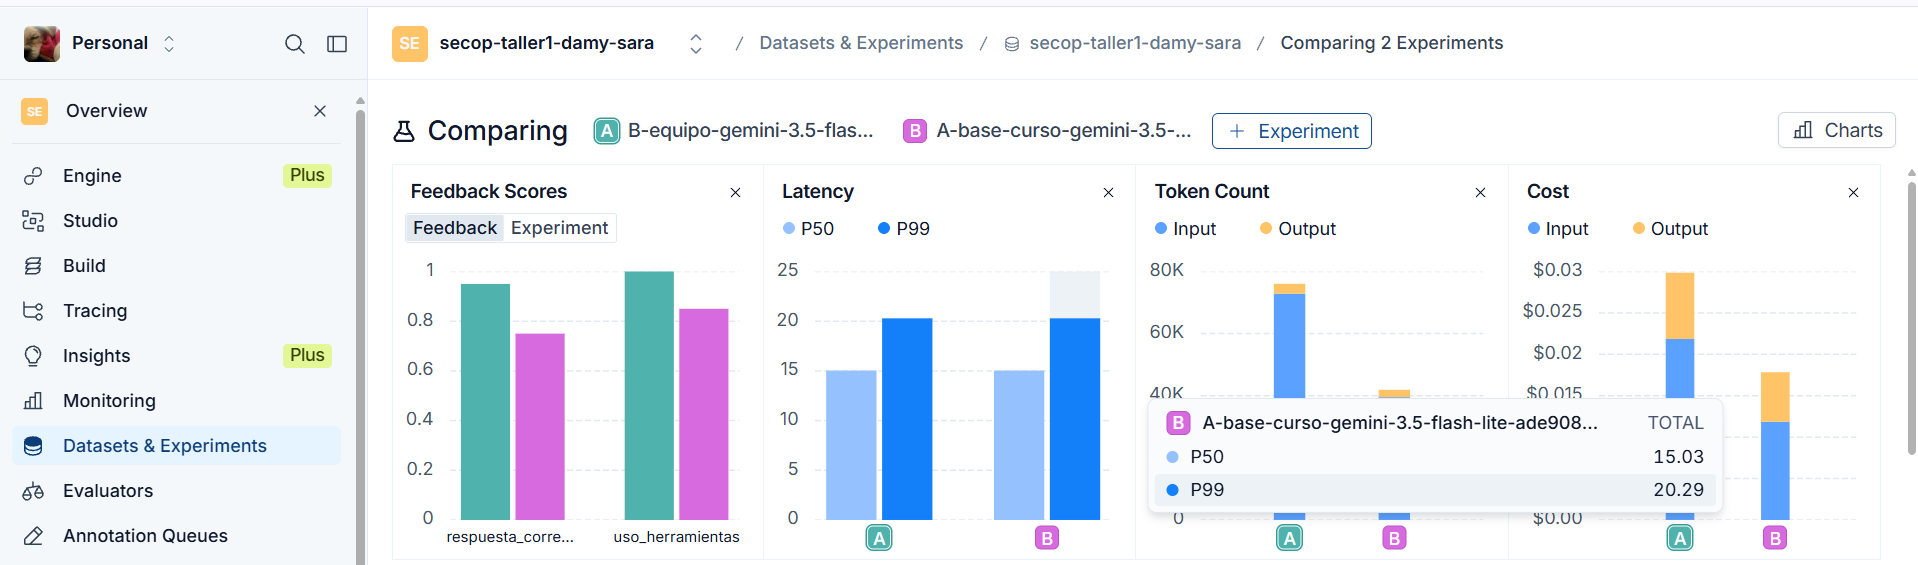

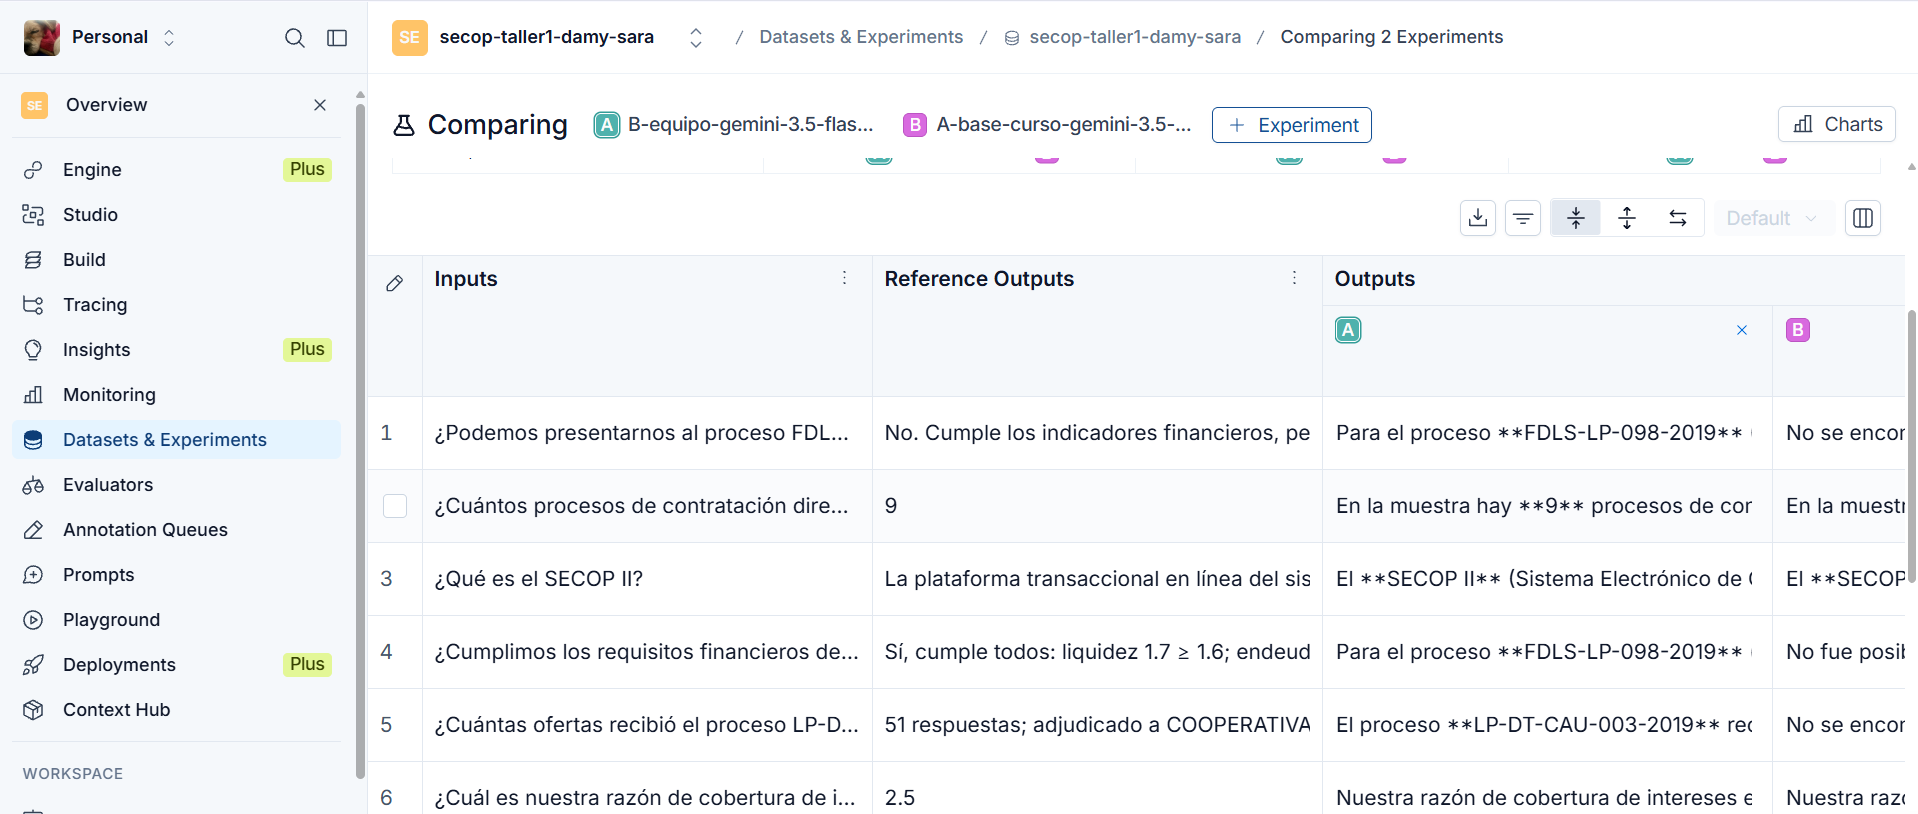